# Eksplorasi Python untuk Permasalahan Probabilitas
**Mata kuliah:** Statistika dan Probabilitas

Definisi klasik dan frekuensi relatif, sample space dan event, gabungan/komplemen, probabilitas bersyarat, probabilitas total, Teorema Bayes, serta permutasi dan kombinasi. Soal berkode berakhiran **0** (A0, A0B, B0, B0B, D0, F0, F0B, G0) adalah **contoh yang diambil dari modul**, sehingga angkanya dapat dicocokkan langsung dengan slide.
Selebihnya soal dibuat dengan bantuan AI (Claude), lalu diperiksa. Pada setiap soal, baris `Cek vs manual` membandingkan hasil Python dengan angka yang dihitung tangan pada bagian *Hitungan manual*. Untuk simulasi hasilnya hanya mendekati, jadi dipakai toleransi yang tertulis pada label pembandingnya.

| Kode | Topik (sesuai modul) |
|---|---|
| A | Probabilitas dasar: definisi klasik, frekuensi relatif, sample space dan event |
| B | Permutasi dan kombinasi (empat kasus pengambilan sampel) |
| C | Gabungan, irisan, dan komplemen event |
| D | Probabilitas bersyarat |
| E | Event independen |
| F | Probabilitas total dan Teorema Bayes |
| G | Simulasi Monte Carlo (menaksir probabilitas dengan frekuensi relatif) |

**Padanan istilah modul ↔ notasi Python:** prob(A) = P(A) dalam kode; *sample space* = himpunan semua hasil (`S`); *sample point* = satu elemen S; *event* = subset S (`set`/`list` Python); fungsi Excel FACT, PERMUT, COMBIN = `math.factorial`, `math.perm`, `math.comb`.

In [ ]:
import math, itertools, random
from fractions import Fraction
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)       # seed tetap agar hasil simulasi bisa diulang
random.seed(42)

def cocok(manual, python, tol=1e-9):
    """Bandingkan hasil manual dan hasil Python."""
    ok = abs(float(manual) - float(python)) < tol
    return "SAMA" if ok else "BERBEDA"
print("Library siap dipakai. numpy", np.__version__, "| pandas", pd.__version__)

Library siap dipakai. numpy 2.4.6 | pandas 2.2.3


---
## Topik A — Probabilitas Dasar (Klasik)
Rumus: **P(A) = n(A) / n(S)**, dengan syarat setiap hasil dalam ruang sampel S punya peluang sama.
Library utama: `itertools.product`, `fractions.Fraction`, `collections.Counter`.

#### Soal A0 — Tabel frekuensi relatif keterlambatan bus (contoh modul, Definisi 2)

**Soal:** Modul mencatat keterlambatan kedatangan bus pada 30 jadwal: keterlambatan 1 sampai 10 menit dengan frekuensi 2, 3, 8, 4, 5, 3, 2, 0, 1, 2. Susun tabel frekuensi relatif (probabilitas empiris), lalu hitung prob(keterlambatan = 3 menit), prob(keterlambatan ≤ 3 menit), dan prob(keterlambatan ≥ 6 menit).

**Hitungan manual:**

Frekuensi relatif = frekuensi / 30. Jumlah frekuensi = 2+3+8+4+5+3+2+0+1+2 = 30.
prob(3 menit) = 8/30 = 0,2667 (di modul ditulis 0,27)
prob(≤ 3) = (2+3+8)/30 = 13/30 = 0,4333
prob(≥ 6) = (3+2+0+1+2)/30 = 8/30 = 0,2667
Probabilitas ini adalah perkiraan berdasarkan observasi (Definisi 2 modul), bukan himpunan semua kemungkinan (Definisi 1).

                       Frekuensi  Frek. relatif Persentase
Keterlambatan (menit)                                     
1                              2           0.07         7%
2                              3           0.10        10%
3                              8           0.27        27%
4                              4           0.13        13%
5                              5           0.17        17%
6                              3           0.10        10%
7                              2           0.07         7%
8                              0           0.00         0%
9                              1           0.03         3%
10                             2           0.07         7%
Jumlah frekuensi = 30 | jumlah frek. relatif = 1.0000
prob(3 menit) = 0.2667 | prob(<=3) = 0.4333 | prob(>=6) = 0.2667


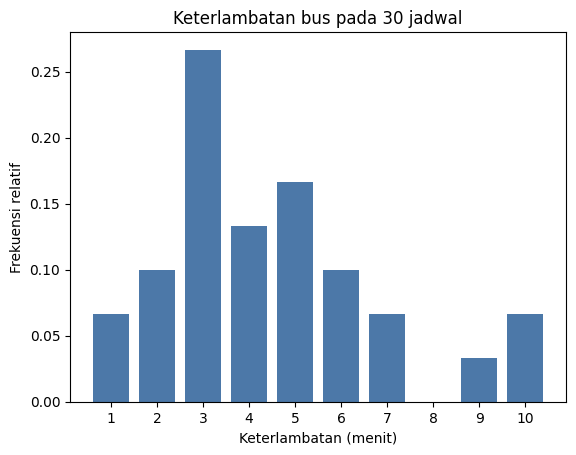

Cek vs manual (jumlah frek. relatif): SAMA
Cek vs manual (prob(3 menit)): SAMA
Cek vs manual (prob(<=3)): SAMA
Cek vs manual (prob(>=6)): SAMA


In [ ]:
frek = pd.DataFrame({"Keterlambatan (menit)": range(1, 11),
                     "Frekuensi": [2, 3, 8, 4, 5, 3, 2, 0, 1, 2]}).set_index("Keterlambatan (menit)")
n_jadwal = frek["Frekuensi"].sum()
frek["Frek. relatif"] = (frek["Frekuensi"] / n_jadwal).round(2)
frek["Persentase"] = (100 * frek["Frekuensi"] / n_jadwal).round(0).astype(int).astype(str) + "%"
print(frek)
a0_total = (frek["Frekuensi"] / n_jadwal).sum()
a0_rel3 = frek.loc[3, "Frekuensi"] / n_jadwal
a0_le3 = frek.loc[1:3, "Frekuensi"].sum() / n_jadwal
a0_ge6 = frek.loc[6:10, "Frekuensi"].sum() / n_jadwal
print(f"Jumlah frekuensi = {n_jadwal} | jumlah frek. relatif = {a0_total:.4f}")
print(f"prob(3 menit) = {a0_rel3:.4f} | prob(<=3) = {a0_le3:.4f} | prob(>=6) = {a0_ge6:.4f}")

plt.bar(frek.index, frek["Frekuensi"] / n_jadwal, color="#4C78A8")
plt.xlabel("Keterlambatan (menit)"); plt.ylabel("Frekuensi relatif"); plt.xticks(range(1, 11))
plt.title("Keterlambatan bus pada 30 jadwal")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (jumlah frek. relatif):", cocok(1, a0_total, 1e-09))
print("Cek vs manual (prob(3 menit)):", cocok(8/30, a0_rel3, 1e-09))
print("Cek vs manual (prob(<=3)):", cocok(13/30, a0_le3, 1e-09))
print("Cek vs manual (prob(>=6)):", cocok(8/30, a0_ge6, 1e-09))

**Interpretasi A0:** Keterlambatan yang paling sering adalah 3 menit dengan frekuensi relatif 0,27 (sekitar 27%). Jumlah seluruh frekuensi relatif sama dengan 1, sesuai syarat bahwa jumlah bobot sample space = 1, dan setiap nilainya berada pada kisaran 0 sampai 1. Peluang terlambat paling lama 3 menit adalah 43,3%, sedangkan terlambat 6 menit atau lebih 26,7%. Angka ini hanya perkiraan dari 30 jadwal; dengan jadwal lain nilainya bisa sedikit berbeda (lihat soal G0).

#### Soal A0B — Sample space dan event pada tiga stasiun (contoh modul)

**Soal:** Sebuah DAS memiliki 3 stasiun. Tiap stasiun perlu (y) atau tidak perlu (n) penggantian alat. Anggap kedelapan hasil berbobot sama. (a) Tuliskan sample space S1 dan S2 (jumlah stasiun yang perlu diganti). (b) Hitung prob event A (paling sedikit 2 stasiun perlu diganti), B (tidak ada yang perlu diganti), dan C (tepat 2 stasiun perlu diganti).

**Hitungan manual:**

S1 memuat 2³ = 8 titik sampel, tiap titik berbobot 1/8. S2 = {0, 1, 2, 3} dengan bobot 1/8, 3/8, 3/8, 1/8.
A = {yyy, yyn, yny, nyy} → prob(A) = 4/8 = 0,5
B = {nnn} → prob(B) = 1/8 = 0,125
C = {yyn, yny, nyy} → prob(C) = 3/8 = 0,375
Dengan S2: prob(A) = prob(2) + prob(3) = 3/8 + 1/8 = 0,5 (sama, tetapi informasi stasiun mana yang perlu diganti hilang).

In [ ]:
S1 = list(itertools.product("yn", repeat=3))          # sample space alternatif 1 (8 titik sampel)
print("S1 =", ["".join(s) for s in S1])
A = [s for s in S1 if s.count("y") >= 2]
B = [s for s in S1 if s.count("y") == 0]
C = [s for s in S1 if s.count("y") == 2]
a0b_A, a0b_B, a0b_C = Fraction(len(A), len(S1)), Fraction(len(B), len(S1)), Fraction(len(C), len(S1))
print(f"prob(A) = {a0b_A} | prob(B) = {a0b_B} | prob(C) = {a0b_C}")

S2 = Counter(s.count("y") for s in S1)                 # sample space alternatif 2 = {0,1,2,3}
bobot_S2 = {k: Fraction(v, len(S1)) for k, v in sorted(S2.items())}
print("S2 dan bobot:", {k: str(v) for k, v in bobot_S2.items()}, "| jumlah bobot =", sum(bobot_S2.values()))
a0b_A2 = bobot_S2[2] + bobot_S2[3]
print("prob(A) lewat S2 =", a0b_A2)

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (prob(A)):", cocok(4/8, a0b_A, 1e-09))
print("Cek vs manual (prob(B)):", cocok(1/8, a0b_B, 1e-09))
print("Cek vs manual (prob(C)):", cocok(3/8, a0b_C, 1e-09))
print("Cek vs manual (prob(A) lewat S2):", cocok(3/8 + 1/8, a0b_A2, 1e-09))

S1 = ['yyy', 'yyn', 'yny', 'ynn', 'nyy', 'nyn', 'nny', 'nnn']
prob(A) = 1/2 | prob(B) = 1/8 | prob(C) = 3/8
S2 dan bobot: {0: '1/8', 1: '3/8', 2: '3/8', 3: '1/8'} | jumlah bobot = 1
prob(A) lewat S2 = 1/2
Cek vs manual (prob(A)): SAMA
Cek vs manual (prob(B)): SAMA
Cek vs manual (prob(C)): SAMA
Cek vs manual (prob(A) lewat S2): SAMA


**Interpretasi A0B:** Peluang paling sedikit 2 stasiun perlu diganti adalah 1/2 = 0,50; peluang tidak ada yang perlu diganti hanya 1/8 = 0,125; peluang tepat 2 stasiun 3/8 = 0,375. S2 memberi hasil prob(A) yang sama (1/2) tetapi lebih ringkas, dengan harga informasi yang berkurang. Jumlah bobot setiap sample space = 1. Catatan: bobot sama berarti tiap stasiun dianggap perlu diganti dengan peluang 1/2 secara independen; ini hanya asumsi contoh.

#### Soal A1 — Jumlah dua dadu = 7

**Soal:** Dua dadu bersisi 6 dilempar bersamaan. Berapa peluang jumlah mata kedua dadu sama dengan 7?

**Hitungan manual:**

n(S) = 6 × 6 = 36. Pasangan berjumlah 7: (1,6),(2,5),(3,4),(4,3),(5,2),(6,1) → n(A) = 6.
P(A) = 6/36 = 1/6 ≈ 0,1667

In [ ]:
S = list(itertools.product(range(1, 7), repeat=2))     # ruang sampel 36 pasangan
A = [s for s in S if sum(s) == 7]
a1_p = Fraction(len(A), len(S))
print("n(S) =", len(S), "| n(A) =", len(A))
print("P(jumlah=7) =", a1_p, "=", round(float(a1_p), 4))
print("Manual vs Python:", cocok(1/6, a1_p))

n(S) = 36 | n(A) = 6
P(jumlah=7) = 1/6 = 0.1667
Manual vs Python: SAMA


**Interpretasi A1:** Peluang jumlah 7 adalah 1/6 ≈ 0,1667, atau sekitar 16,7%. Angka 7 adalah jumlah yang paling mungkin muncul pada dua dadu karena punya kombinasi terbanyak (6 dari 36). Hasil Python sama dengan hitungan manual.

#### Soal A2 — Tiga lemparan koin

**Soal:** Sebuah koin adil dilempar 3 kali. Berapa peluang muncul tepat 2 kali Angka (A)?

**Hitungan manual:**

n(S) = 2³ = 8. Hasil dengan tepat dua A: AAG, AGA, GAA → n(E) = 3.
P(E) = 3/8 = 0,375

In [ ]:
S = list(itertools.product("AG", repeat=3))
E = [s for s in S if s.count("A") == 2]
a2_p = Fraction(len(E), len(S))
print("Ruang sampel:", ["".join(s) for s in S])
print("Kejadian    :", ["".join(s) for s in E])
print("P(tepat 2 Angka) =", a2_p, "=", float(a2_p))
print("Manual vs Python:", cocok(3/8, a2_p))

Ruang sampel: ['AAA', 'AAG', 'AGA', 'AGG', 'GAA', 'GAG', 'GGA', 'GGG']
Kejadian    : ['AAG', 'AGA', 'GAA']
P(tepat 2 Angka) = 3/8 = 0.375
Manual vs Python: SAMA


**Interpretasi A2:** Peluangnya 3/8 = 0,375. Dari 8 kemungkinan hasil, hanya 3 yang memuat tepat dua Angka, jadi kejadian ini cukup sering (37,5%) tetapi bukan yang paling sering muncul.

#### Soal A3 — Pengambilan satu kartu remi

**Soal:** Satu kartu diambil acak dari 52 kartu remi. Berapa peluang terambil kartu As, dan berapa peluang terambil kartu Hati?

**Hitungan manual:**

P(As) = 4/52 = 1/13 ≈ 0,0769
P(Hati) = 13/52 = 1/4 = 0,25

In [ ]:
jenis = ["Hati", "Wajik", "Keriting", "Sekop"]
nilai = ["A"] + [str(i) for i in range(2, 11)] + ["J", "Q", "K"]
kartu = list(itertools.product(nilai, jenis))
a3_as = Fraction(sum(1 for k in kartu if k[0] == "A"), len(kartu))
a3_hati = Fraction(sum(1 for k in kartu if k[1] == "Hati"), len(kartu))
print("Jumlah kartu:", len(kartu))
print("P(As)   =", a3_as, "=", round(float(a3_as), 4))
print("P(Hati) =", a3_hati, "=", float(a3_hati))
print("Manual vs Python:", cocok(1/13, a3_as), "dan", cocok(0.25, a3_hati))

Jumlah kartu: 52
P(As)   = 1/13 = 0.0769
P(Hati) = 1/4 = 0.25
Manual vs Python: SAMA dan SAMA


**Interpretasi A3:** P(As) = 1/13 ≈ 0,0769 (sekitar 7,7%), sedangkan P(Hati) = 1/4 = 25%. Hati lebih mungkin karena ada 13 kartu Hati dibanding hanya 4 As. Hasil Python sama dengan manual.

#### Soal A4 — Menebak PIN 4 digit

**Soal:** Sebuah PIN terdiri dari 4 digit (0–9, boleh berulang). (a) Berapa peluang menebak PIN yang benar pada satu kali tebakan? (b) Berapa peluang sebuah PIN memiliki semua digit berbeda?

**Hitungan manual:**

(a) Jumlah PIN = 10⁴ = 10.000 → P = 1/10.000 = 0,0001
(b) Digit berbeda: 10 × 9 × 8 × 7 = 5.040 → P = 5.040/10.000 = 0,504

In [ ]:
a4_total = 10**4
a4_a = Fraction(1, a4_total)
semua = itertools.product(range(10), repeat=4)
a4_berbeda = sum(1 for p in semua if len(set(p)) == 4)
a4_b = Fraction(a4_berbeda, a4_total)
a4_rep = 1 - a4_b
print("Total PIN        :", a4_total)
print("(a) P(tebakan benar) =", float(a4_a))
print("(b) PIN digit berbeda:", a4_berbeda, "-> P =", float(a4_b))
print("Manual vs Python:", cocok(0.0001, a4_a), "dan", cocok(0.504, a4_b))

Total PIN        : 10000
(a) P(tebakan benar) = 0.0001
(b) PIN digit berbeda: 5040 -> P = 0.504
Manual vs Python: SAMA dan SAMA


**Interpretasi A4:** (a) Menebak PIN hanya berhasil dengan peluang 0,0001 (1 banding 10.000) sehingga PIN 4 digit lemah terhadap serangan brute force tanpa pembatasan percobaan. (b) 5.040 dari 10.000 PIN punya semua digit berbeda, yaitu 50,4%; sisanya 49,6% PIN justru memiliki digit berulang.

---
## Topik B — Permutasi dan Kombinasi
- Permutasi (urutan penting): P(n,r) = n!/(n−r)!
- Kombinasi (urutan tidak penting): C(n,r) = n!/(r!(n−r)!)
- Library: `math.factorial`, `math.perm`, `math.comb`

#### Soal B0B — Pendekatan Stirling untuk faktorial

**Soal:** Modul memberi pendekatan Stirling n! ≈ √(2π) · e^(−n) · n^(n+1/2). Bandingkan dengan n! eksak untuk n = 5, 10, 20.

**Hitungan manual:**

n = 5: √(2π) = 2,5066; e⁻⁵ = 0,006738; 5^5,5 = 6.987,7 → hasil ≈ 118,02 (eksak 120)
Galat relatif = (120 − 118,02)/120 ≈ 1,65%.

In [ ]:
baris = []
for n in (5, 10, 20):
    eksak = math.factorial(n)
    stirling = math.sqrt(2 * math.pi) * math.exp(-n) * n ** (n + 0.5)
    baris.append((n, eksak, stirling, abs(eksak - stirling) / eksak))
tab = pd.DataFrame(baris, columns=["n", "n! eksak", "Stirling", "galat relatif"])
print(tab.to_string(index=False, formatters={"n! eksak": "{:.4e}".format, "Stirling": "{:.4e}".format, "galat relatif": "{:.2%}".format}))
b0b_n5 = baris[0][2]
b0b_e5, b0b_e10, b0b_e20 = baris[0][3], baris[1][3], baris[2][3]

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (Stirling n=5, toleransi 0.01):", cocok(118.02, b0b_n5, 0.01))

 n   n! eksak   Stirling galat relatif
 5 1.2000e+02 1.1802e+02         1.65%
10 3.6288e+06 3.5987e+06         0.83%
20 2.4329e+18 2.4228e+18         0.42%
Cek vs manual (Stirling n=5, toleransi 0.01): SAMA


**Interpretasi B0B:** Untuk n = 5 pendekatan Stirling menghasilkan 118,02 (eksak 120) dengan galat 1,65%. Galat mengecil menjadi 0,83% untuk n = 10 dan 0,42% untuk n = 20. Pendekatan Stirling makin akurat saat n membesar, berguna ketika n! terlalu besar untuk dihitung langsung.

#### Soal B1 — Urutan pengerjaan tugas

**Soal:** Ada 5 tugas berbeda yang harus dikerjakan satu per satu. Berapa banyak urutan pengerjaan yang mungkin?

**Hitungan manual:**

5! = 5 × 4 × 3 × 2 × 1 = 120

In [ ]:
b1_n = math.factorial(5)
b1_cek = len(list(itertools.permutations(range(5))))
print("5! =", b1_n, "| cacah dengan itertools.permutations =", b1_cek)
print("Manual vs Python:", cocok(120, b1_n))

5! = 120 | cacah dengan itertools.permutations = 120
Manual vs Python: SAMA


**Interpretasi B1:** Terdapat 120 urutan berbeda. Pencacahan langsung dengan `itertools.permutations` memberi 120, sama dengan rumus faktorial. Jumlah urutan tumbuh sangat cepat: 10 tugas sudah menghasilkan 3.628.800 urutan.

#### Soal B2 — Memilih pengurus (permutasi)

**Soal:** Dari 10 mahasiswa dipilih ketua, wakil, dan sekretaris (jabatan berbeda). Berapa banyak susunan pengurus?

**Hitungan manual:**

P(10,3) = 10 × 9 × 8 = 720

In [ ]:
b2_n = math.perm(10, 3)
b2_cek = len(list(itertools.permutations(range(10), 3)))
print("P(10,3) =", b2_n, "| cek itertools =", b2_cek)
print("Manual vs Python:", cocok(720, b2_n))

P(10,3) = 720 | cek itertools = 720
Manual vs Python: SAMA


**Interpretasi B2:** Ada 720 susunan. Urutan penting karena jabatan berbeda: orang yang sama sebagai ketua dan sebagai wakil dihitung sebagai susunan yang berbeda.

#### Soal B3 — Memilih tim (kombinasi)

**Soal:** Dari 12 mahasiswa dipilih tim 4 orang tanpa membedakan jabatan. Berapa banyak tim yang mungkin?

**Hitungan manual:**

C(12,4) = 12!/(4! 8!) = (12×11×10×9)/(4×3×2×1) = 11.880/24 = 495

In [ ]:
b3_n = math.comb(12, 4)
b3_cek = len(list(itertools.combinations(range(12), 4)))
print("C(12,4) =", b3_n, "| cek itertools =", b3_cek)
print("Perbandingan dengan permutasi P(12,4) =", math.perm(12, 4), "-> rasio =", math.perm(12, 4) // b3_n, "(= 4!)")

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (C(12,4), toleransi 0.5):", cocok(495, b3_n, 0.5))

C(12,4) = 495 | cek itertools = 495
Perbandingan dengan permutasi P(12,4) = 11880 -> rasio = 24 (= 4!)
Cek vs manual (C(12,4), toleransi 0.5): SAMA


**Interpretasi B3:** Terdapat 495 tim berbeda. Permutasi P(12,4) = 11.880 lebih besar tepat 4! = 24 kali karena setiap tim yang sama dihitung dalam 24 urutan berbeda. Kombinasi membuang informasi urutan.

#### Soal B4 — Lima kartu semuanya Hati

**Soal:** Dari 52 kartu diambil 5 kartu sekaligus. Berapa peluang kelimanya kartu Hati?

**Hitungan manual:**

n(S) = C(52,5) = 2.598.960; n(A) = C(13,5) = 1.287
P(A) = 1.287 / 2.598.960 ≈ 0,000495

In [ ]:
b4_s = math.comb(52, 5)
b4_a = math.comb(13, 5)
b4_p = b4_a / b4_s
print("C(52,5) =", b4_s, "| C(13,5) =", b4_a)
print("P(5 Hati) =", b4_p, "=", f"{b4_p:.4%}")
print("Sekitar 1 banding", round(1 / b4_p))
print("Manual vs Python:", cocok(1287 / 2598960, b4_p))

C(52,5) = 2598960 | C(13,5) = 1287
P(5 Hati) = 0.0004951980792316927 = 0.0495%
Sekitar 1 banding 2019
Manual vs Python: SAMA


**Interpretasi B4:** Peluangnya hanya 0,000495 atau sekitar 0,050%: kira-kira 1 dari 2.019 pengambilan. Kejadian ini sangat jarang (dalam poker disebut flush Hati).

#### Soal B5 — Ruang password

**Soal:** Password 8 karakter. Bandingkan jumlah kemungkinan password jika (a) hanya huruf kecil (26 simbol) dan (b) huruf besar+kecil+angka (62 simbol). Jika penyerang mencoba 1 miliar password per detik, berapa lama untuk mencoba semuanya?

**Hitungan manual:**

(a) 26⁸ = 208.827.064.576 ≈ 2,09 × 10¹¹
(b) 62⁸ = 218.340.105.584.896 ≈ 2,18 × 10¹⁴

In [ ]:
b5_a, b5_b = 26**8, 62**8
laju = 1e9
b5_wkt_a = b5_a / laju
b5_wkt_b = b5_b / laju / 3600
print(f"(a) 26^8 = {b5_a:,} -> {b5_wkt_a:.1f} detik")
print(f"(b) 62^8 = {b5_b:,} -> {b5_wkt_b:.1f} jam")
b5_rasio = b5_b / b5_a
print(f"Rasio (b)/(a) = {b5_rasio:.0f}x lebih banyak")

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (26^8, toleransi 0.5):", cocok(208827064576, b5_a, 0.5))
print("Cek vs manual (62^8, toleransi 0.5):", cocok(218340105584896, b5_b, 0.5))

(a) 26^8 = 208,827,064,576 -> 208.8 detik
(b) 62^8 = 218,340,105,584,896 -> 60.7 jam
Rasio (b)/(a) = 1046x lebih banyak
Cek vs manual (26^8, toleransi 0.5): SAMA
Cek vs manual (62^8, toleransi 0.5): SAMA


**Interpretasi B5:** Password huruf kecil saja hanya memerlukan sekitar 209 detik untuk dicoba semuanya, sedangkan campuran 62 simbol membutuhkan sekitar 61 jam. Menambah ragam simbol membuat ruang kemungkinan 1.046 kali lebih besar — alasan matematis mengapa password sebaiknya memadukan huruf besar, kecil, dan angka.

---
## Topik C — Gabungan, Irisan, dan Komplemen Kejadian
- P(A ∪ B) = P(A) + P(B) − P(A ∩ B)
- Kejadian saling lepas: P(A ∩ B) = 0
- Komplemen: P(A') = 1 − P(A)

#### Soal C1 — As atau Hati

**Soal:** Satu kartu diambil dari 52 kartu. Berapa peluang kartu tersebut As atau Hati?

**Hitungan manual:**

P(As) = 4/52, P(Hati) = 13/52, P(As ∩ Hati) = 1/52
P(As ∪ Hati) = 4/52 + 13/52 − 1/52 = 16/52 = 4/13 ≈ 0,3077

In [ ]:
jenis = ["Hati", "Wajik", "Keriting", "Sekop"]
nilai = ["A"] + [str(i) for i in range(2, 11)] + ["J", "Q", "K"]
S = set(itertools.product(nilai, jenis))
A = {k for k in S if k[0] == "A"}
B = {k for k in S if k[1] == "Hati"}
n = len(S)
c1_rumus = Fraction(len(A), n) + Fraction(len(B), n) - Fraction(len(A & B), n)
c1_langsung = Fraction(len(A | B), n)
print("Dengan rumus   :", c1_rumus, "=", round(float(c1_rumus), 4))
print("Himpunan gabungan:", c1_langsung)
print("Manual vs Python:", cocok(4 / 13, c1_rumus))

Dengan rumus   : 4/13 = 0.3077
Himpunan gabungan: 4/13
Manual vs Python: SAMA


**Interpretasi C1:** P(As ∪ Hati) = 4/13 ≈ 0,3077. Tanpa mengurangi irisan, As Hati akan terhitung dua kali (hasilnya 17/52). Operasi himpunan Python (`|` dan `&`) memberi hasil yang sama dengan rumus.

#### Soal C2 — Genap atau lebih dari 4

**Soal:** Satu dadu dilempar. A = mata genap, B = mata lebih dari 4. Hitung P(A ∪ B).

**Hitungan manual:**

A = {2,4,6}, B = {5,6}, A ∩ B = {6}
P(A ∪ B) = 3/6 + 2/6 − 1/6 = 4/6 = 2/3 ≈ 0,6667

In [ ]:
S = set(range(1, 7))
A = {x for x in S if x % 2 == 0}
B = {x for x in S if x > 4}
c2_p = Fraction(len(A | B), len(S))
print("A =", A, "| B =", B, "| A∩B =", A & B, "| A∪B =", A | B)
print("P(A∪B) =", c2_p, "=", round(float(c2_p), 4))
print("Manual vs Python:", cocok(2 / 3, c2_p))

A = {2, 4, 6} | B = {5, 6} | A∩B = {6} | A∪B = {2, 4, 5, 6}
P(A∪B) = 2/3 = 0.6667
Manual vs Python: SAMA


**Interpretasi C2:** P(A ∪ B) = 2/3 ≈ 0,6667. Mata 6 berada di A dan B sekaligus, sehingga harus dihitung sekali saja. Hanya mata 1 dan 3 yang tidak termasuk kejadian gabungan.

#### Soal C3 — Mahasiswa pengambil mata kuliah

**Soal:** Di suatu kelas, 60% mahasiswa mengambil Python, 50% mengambil Java, dan 30% mengambil keduanya. Hitung peluang seorang mahasiswa (a) mengambil minimal salah satu, (b) tidak mengambil keduanya, (c) hanya mengambil Python.

**Hitungan manual:**

(a) 0,6 + 0,5 − 0,3 = 0,8
(b) 1 − 0,8 = 0,2
(c) P(Python) − P(keduanya) = 0,6 − 0,3 = 0,3

In [ ]:
pP, pJ, pPJ = 0.6, 0.5, 0.3
c3_a = pP + pJ - pPJ
c3_b = 1 - c3_a
c3_c = pP - pPJ
print(f"(a) P(Python atau Java)     = {c3_a:.2f}")
print(f"(b) P(tidak keduanya)       = {c3_b:.2f}")
print(f"(c) P(hanya Python)         = {c3_c:.2f}")
print("Manual vs Python:", cocok(0.8, c3_a), cocok(0.2, c3_b), cocok(0.3, c3_c))

(a) P(Python atau Java)     = 0.80
(b) P(tidak keduanya)       = 0.20
(c) P(hanya Python)         = 0.30
Manual vs Python: SAMA SAMA SAMA


**Interpretasi C3:** 80% mahasiswa mengambil minimal satu dari dua mata kuliah, sehingga 20% tidak mengambil keduanya. Hanya 30% yang mengambil Python tanpa Java. Pola ini sering dipakai pada analisis irisan pengguna dua fitur produk.

#### Soal C4 — Kejadian saling lepas

**Soal:** Satu dadu dilempar. A = mata {1,2}, B = mata {5,6}. Apakah A dan B saling lepas? Hitung P(A ∪ B).

**Hitungan manual:**

A ∩ B = ∅ sehingga saling lepas. P(A ∪ B) = 2/6 + 2/6 = 4/6 = 2/3.

In [ ]:
A, B = {1, 2}, {5, 6}
c4_irisan = A & B
c4_p = Fraction(len(A), 6) + Fraction(len(B), 6)
print("A ∩ B =", c4_irisan, "-> saling lepas?", len(c4_irisan) == 0)
print("P(A∪B) =", c4_p, "=", round(float(c4_p), 4))
print("Cek langsung:", Fraction(len(A | B), 6))

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (P(A atau B)):", cocok(2/3, c4_p, 1e-09))

A ∩ B = set() -> saling lepas? True
P(A∪B) = 2/3 = 0.6667
Cek langsung: 2/3
Cek vs manual (P(A atau B)): SAMA


**Interpretasi C4:** Karena irisan kosong, peluang gabungan cukup dijumlahkan: 2/3 ≈ 0,6667. Rumus umum tetap berlaku dengan P(A ∩ B) = 0.

#### Soal C5 — Tiga kejadian (inklusi–eksklusi)

**Soal:** Dua dadu dilempar. A = jumlah genap, B = dadu pertama bernilai 6, C = jumlah ≥ 10. Hitung P(A ∪ B ∪ C) dengan rumus inklusi–eksklusi dan bandingkan dengan pencacahan langsung.

**Hitungan manual:**

P(A∪B∪C) = P(A)+P(B)+P(C) − P(A∩B) − P(A∩C) − P(B∩C) + P(A∩B∩C)
P(A)=18/36, P(B)=6/36, P(C)=6/36, P(A∩B)=3/36, P(A∩C)=4/36, P(B∩C)=3/36, P(A∩B∩C)=2/36
= (18+6+6−3−4−3+2)/36 = 22/36 = 11/18 ≈ 0,6111

In [ ]:
S = set(itertools.product(range(1, 7), repeat=2))
A = {s for s in S if sum(s) % 2 == 0}
B = {s for s in S if s[0] == 6}
C = {s for s in S if sum(s) >= 10}
P = lambda E: Fraction(len(E), len(S))
c5_rumus = P(A) + P(B) + P(C) - P(A & B) - P(A & C) - P(B & C) + P(A & B & C)
c5_langsung = P(A | B | C)
print("P(A)=", P(A), " P(B)=", P(B), " P(C)=", P(C))
print("Inklusi-eksklusi :", c5_rumus, "=", round(float(c5_rumus), 4))
print("Pencacahan langsung:", c5_langsung)
print("Sama?", c5_rumus == c5_langsung)

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (inklusi-eksklusi):", cocok(22/36, c5_rumus, 1e-09))

P(A)= 1/2  P(B)= 1/6  P(C)= 1/6
Inklusi-eksklusi : 11/18 = 0.6111
Pencacahan langsung: 11/18
Sama? True
Cek vs manual (inklusi-eksklusi): SAMA


**Interpretasi C5:** Rumus inklusi–eksklusi memberi 11/18 ≈ 0,6111, identik dengan pencacahan langsung (11/18). Untuk tiga kejadian, irisan berpasangan dikurangkan lalu irisan ketiganya ditambahkan kembali agar tidak ada hasil yang terhitung berlebih.

---
## Topik D — Probabilitas Bersyarat
**P(A | B) = P(A ∩ B) / P(B)**, dengan P(B) > 0. Aturan perkalian: P(A ∩ B) = P(B) · P(A | B).
Library: `itertools`, `pandas.crosstab`, `Fraction`.

#### Soal D0 — Hujan beruntun (contoh modul)

**Soal:** Data modul: hari hujan setelah hari hujan = 0,444; hari tak hujan setelah hari hujan = 0,556; hari tak hujan setelah hari tak hujan = 0,724; hari hujan setelah hari tak hujan = 0,276. Jika hari ini hujan, berapa probabilitas 2 hari berikutnya juga hujan? Hitung juga keempat kemungkinan jalur 2 hari berikutnya.

**Hitungan manual:**

prob(hujan, hujan | hari ini hujan) = prob(h|h) × prob(h|h) = 0,444 × 0,444 = 0,1971
Jalur lain: (hujan, tak hujan) = 0,444 × 0,556 = 0,2469; (tak hujan, hujan) = 0,556 × 0,276 = 0,1535; (tak hujan, tak hujan) = 0,556 × 0,724 = 0,4025. Jumlah keempatnya = 1.

In [ ]:
trans = {"hujan":     {"hujan": 0.444, "tak hujan": 0.556},
         "tak hujan": {"hujan": 0.276, "tak hujan": 0.724}}
jalur = {}
for h1 in trans["hujan"]:
    for h2 in trans[h1]:
        jalur[("hujan", h1, h2)] = trans["hujan"][h1] * trans[h1][h2]       # aturan perkalian
for j, v in jalur.items():
    print(" -> ".join(j), f": {v:.4f}")
d0_hh = jalur[("hujan", "hujan", "hujan")]
d0_total = sum(jalur.values())
print(f"prob(2 hari berikutnya hujan | hari ini hujan) = {d0_hh:.4f} | jumlah semua jalur = {d0_total:.4f}")

N = 200_000                                                             # simulasi rantai 2 langkah
hari1 = rng.random(N) < 0.444
hari2 = rng.random(N) < np.where(hari1, 0.444, 0.276)
d0_sim = np.mean(hari1 & hari2)
print(f"Simulasi = {d0_sim:.4f}")

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (2 hari hujan):", cocok(0.444*0.444, d0_hh, 1e-09))
print("Cek vs manual (jumlah jalur):", cocok(1, d0_total, 1e-09))
print("Cek vs manual (simulasi, toleransi 0.005):", cocok(0.444*0.444, d0_sim, 0.005))

hujan -> hujan -> hujan : 0.1971
hujan -> hujan -> tak hujan : 0.2469
hujan -> tak hujan -> hujan : 0.1535
hujan -> tak hujan -> tak hujan : 0.4025
prob(2 hari berikutnya hujan | hari ini hujan) = 0.1971 | jumlah semua jalur = 1.0000
Simulasi = 0.1981
Cek vs manual (2 hari hujan): SAMA
Cek vs manual (jumlah jalur): SAMA
Cek vs manual (simulasi, toleransi 0.005): SAMA


**Interpretasi D0:** Jika hari ini hujan, peluang dua hari berikutnya sama-sama hujan adalah 0,1971 (sekitar 19,7%), hasil aturan perkalian prob(A ∩ B) = prob(A) · prob(B|A). Jalur yang paling mungkin justru dua hari tak hujan (sekitar 40,3%). Jumlah keempat jalur 1, dan simulasi 200.000 percobaan memberi 0,1981, mendekati hitungan.

#### Soal D1 — Jumlah 8 jika dadu pertama genap

**Soal:** Dua dadu dilempar. Jika diketahui dadu pertama bernilai genap, berapa peluang jumlah kedua dadu = 8?

**Hitungan manual:**

B (dadu pertama genap) = 18 hasil. A ∩ B: (2,6),(4,4),(6,2) = 3 hasil.
P(A|B) = 3/18 = 1/6 ≈ 0,1667

In [ ]:
S = set(itertools.product(range(1, 7), repeat=2))
A = {s for s in S if sum(s) == 8}
B = {s for s in S if s[0] % 2 == 0}
d1_p = Fraction(len(A & B), len(B))
d1_tanpa = Fraction(len(A), len(S))
print("n(B) =", len(B), "| n(A∩B) =", len(A & B))
print("P(jumlah=8 | dadu1 genap) =", d1_p, "=", round(float(d1_p), 4))
print("P(jumlah=8) tanpa syarat  =", d1_tanpa, "=", round(float(d1_tanpa), 4))
print("Manual vs Python:", cocok(1 / 6, d1_p))

n(B) = 18 | n(A∩B) = 3
P(jumlah=8 | dadu1 genap) = 1/6 = 0.1667
P(jumlah=8) tanpa syarat  = 5/36 = 0.1389
Manual vs Python: SAMA


**Interpretasi D1:** P(A|B) = 1/6 ≈ 0,1667, sedangkan peluang tanpa informasi tambahan adalah 5/36 ≈ 0,1389. Informasi bahwa dadu pertama genap menaikkan peluang jumlah 8 karena ruang sampel menyempit dari 36 menjadi 18 hasil.

#### Soal D2 — Dua As berturut-turut

**Soal:** Dua kartu diambil berturut-turut tanpa pengembalian dari 52 kartu. Jika kartu pertama As, berapa peluang kartu kedua juga As? Berapa peluang keduanya As?

**Hitungan manual:**

P(As2 | As1) = 3/51 = 1/17 ≈ 0,0588
P(As1 ∩ As2) = 4/52 × 3/51 = 12/2652 = 1/221 ≈ 0,00452

In [ ]:
d2_cond = Fraction(3, 51)
d2_joint = Fraction(4, 52) * Fraction(3, 51)
print("P(As2|As1)    =", d2_cond, "=", round(float(d2_cond), 4))
print("P(As1 ∩ As2)  =", d2_joint, "=", round(float(d2_joint), 5))
print("Cek kombinasi : C(4,2)/C(52,2) =", Fraction(math.comb(4, 2), math.comb(52, 2)))

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (P(As2|As1)):", cocok(1/17, d2_cond, 1e-09))
print("Cek vs manual (P(As1 dan As2)):", cocok(1/221, d2_joint, 1e-09))

P(As2|As1)    = 1/17 = 0.0588
P(As1 ∩ As2)  = 1/221 = 0.00452
Cek kombinasi : C(4,2)/C(52,2) = 1/221
Cek vs manual (P(As2|As1)): SAMA
Cek vs manual (P(As1 dan As2)): SAMA


**Interpretasi D2:** Jika As pertama sudah terambil, tersisa 3 As di 51 kartu sehingga peluangnya 0,0588. Peluang kedua kartu As adalah 0,00452 (1 banding 221), sama dengan hasil pendekatan kombinasi. Pada pengambilan tanpa pengembalian, peluang kejadian kedua bergantung pada hasil pertama.

#### Soal D3 — Bug pada dua modul (tabel kontingensi)

**Soal:** Sebuah perangkat lunak memiliki 200 bug: modul A 80 bug (20 kritis) dan modul B 120 bug (18 kritis). Hitung P(kritis | modul A) dan P(modul A | kritis).

**Hitungan manual:**

Total kritis = 38.
P(kritis | A) = 20/80 = 0,25
P(A | kritis) = 20/38 ≈ 0,5263

In [ ]:
data = pd.DataFrame({"Kritis": [20, 18], "Tidak kritis": [60, 102]}, index=["Modul A", "Modul B"])
data["Total"] = data.sum(axis=1)
data.loc["Total"] = data.sum()
print(data)
d3_k_a = data.loc["Modul A", "Kritis"] / data.loc["Modul A", "Total"]
d3_a_k = data.loc["Modul A", "Kritis"] / data.loc["Total", "Kritis"]
print(f"\nP(kritis | A) = {d3_k_a:.4f}")
print(f"P(A | kritis) = {d3_a_k:.4f}")
print("Manual vs Python:", cocok(0.25, d3_k_a), cocok(20 / 38, d3_a_k))

         Kritis  Tidak kritis  Total
Modul A      20            60     80
Modul B      18           102    120
Total        38           162    200

P(kritis | A) = 0.2500
P(A | kritis) = 0.5263
Manual vs Python: SAMA SAMA


**Interpretasi D3:** Seperempat bug di modul A bersifat kritis (P = 0,25), sedangkan di antara semua bug kritis, 52,6% berasal dari modul A. Dua peluang bersyarat ini berbeda karena syarat dan kejadiannya dibalik: P(A|B) ≠ P(B|A).

---
## Topik E — Kejadian Independen
A dan B independen jika **P(A ∩ B) = P(A) · P(B)** (setara dengan P(A|B) = P(A)).

#### Soal E1 — Dua koin

**Soal:** Dua koin dilempar. A = koin pertama Angka, B = koin kedua Angka. Apakah A dan B independen?

**Hitungan manual:**

P(A) = 1/2, P(B) = 1/2, P(A ∩ B) = P(AA) = 1/4 = P(A)·P(B) → independen.

In [ ]:
S = set(itertools.product("AG", repeat=2))
A = {s for s in S if s[0] == "A"}
B = {s for s in S if s[1] == "A"}
P = lambda E: Fraction(len(E), len(S))
e1_irisan, e1_kali = P(A & B), P(A) * P(B)
print("P(A∩B) =", e1_irisan, "| P(A)·P(B) =", e1_kali)
print("Independen?", e1_irisan == e1_kali)

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (P(A dan B)):", cocok(1/4, e1_irisan, 1e-09))

P(A∩B) = 1/4 | P(A)·P(B) = 1/4
Independen? True
Cek vs manual (P(A dan B)): SAMA


**Interpretasi E1:** P(A ∩ B) = 1/4 sama dengan P(A)·P(B) = 1/4, jadi A dan B independen: hasil koin pertama tidak memengaruhi koin kedua.

#### Soal E2 — Dadu pertama genap dan jumlah genap

**Soal:** Dua dadu dilempar. A = dadu pertama genap, B = jumlah kedua dadu genap. Apakah A dan B independen?

**Hitungan manual:**

P(A) = 1/2, P(B) = 18/36 = 1/2, A ∩ B = kedua dadu genap = 9/36 = 1/4.
P(A)·P(B) = 1/4 → independen (walaupun tampak berhubungan).

In [ ]:
S = set(itertools.product(range(1, 7), repeat=2))
A = {s for s in S if s[0] % 2 == 0}
B = {s for s in S if sum(s) % 2 == 0}
P = lambda E: Fraction(len(E), len(S))
e2_irisan, e2_kali = P(A & B), P(A) * P(B)
print("P(A) =", P(A), "| P(B) =", P(B), "| P(A∩B) =", e2_irisan, "| P(A)P(B) =", e2_kali)
print("Independen?", e2_irisan == e2_kali)

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (P(A dan B)):", cocok(1/4, e2_irisan, 1e-09))

P(A) = 1/2 | P(B) = 1/2 | P(A∩B) = 1/4 | P(A)P(B) = 1/4
Independen? True
Cek vs manual (P(A dan B)): SAMA


**Interpretasi E2:** Hasilnya independen karena P(A ∩ B) = 1/4 = P(A)·P(B). Pada soal seperti ini intuisi bisa menipu; uji aljabar atau pencacahan menjadi penentu.

#### Soal E3 — Dadu 6 dan jumlah ≥ 10 (tidak independen)

**Soal:** Dua dadu dilempar. A = dadu pertama 6, B = jumlah ≥ 10. Apakah A dan B independen?

**Hitungan manual:**

P(A) = 1/6, P(B) = 6/36 = 1/6, P(A ∩ B) = {(6,4),(6,5),(6,6)} = 3/36 = 1/12.
P(A)·P(B) = 1/36 ≠ 1/12 → tidak independen.

In [ ]:
S = set(itertools.product(range(1, 7), repeat=2))
A = {s for s in S if s[0] == 6}
B = {s for s in S if sum(s) >= 10}
P = lambda E: Fraction(len(E), len(S))
e3_irisan, e3_kali = P(A & B), P(A) * P(B)
print("P(A∩B) =", e3_irisan, "| P(A)·P(B) =", e3_kali)
print("Independen?", e3_irisan == e3_kali)
print("P(B|A) =", P(A & B) / P(A), "vs P(B) =", P(B))

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (P(A dan B)):", cocok(1/12, e3_irisan, 1e-09))

P(A∩B) = 1/12 | P(A)·P(B) = 1/36
Independen? False
P(B|A) = 1/2 vs P(B) = 1/6
Cek vs manual (P(A dan B)): SAMA


**Interpretasi E3:** P(A ∩ B) = 1/12 jauh lebih besar dari P(A)·P(B) = 1/36, sehingga A dan B tidak independen. Mengetahui dadu pertama 6 menaikkan peluang jumlah ≥ 10 dari 1/6 menjadi 1/2.

#### Soal E4 — Dua server independen

**Soal:** Server X aktif dengan peluang 0,95 dan server Y aktif dengan peluang 0,90, keduanya bekerja independen. Hitung peluang (a) keduanya aktif, (b) minimal satu aktif.

**Hitungan manual:**

(a) 0,95 × 0,90 = 0,855
(b) 1 − (0,05 × 0,10) = 1 − 0,005 = 0,995

In [ ]:
pX, pY = 0.95, 0.90
e4_a = pX * pY
e4_b = 1 - (1 - pX) * (1 - pY)
print(f"(a) P(keduanya aktif)  = {e4_a:.4f}")
print(f"(b) P(minimal satu aktif) = {e4_b:.4f}")
print("Manual vs Python:", cocok(0.855, e4_a), cocok(0.995, e4_b))

(a) P(keduanya aktif)  = 0.8550
(b) P(minimal satu aktif) = 0.9950
Manual vs Python: SAMA SAMA


**Interpretasi E4:** Peluang keduanya aktif sekaligus hanya 0,855, lebih rendah dari masing-masing server. Namun peluang minimal satu aktif naik menjadi 0,995. Inilah alasan sistem redundan (cadangan) dibangun: ketersediaan meningkat dari 90–95% menjadi 99,5%.

---
## Topik F — Probabilitas Total dan Teorema Bayes
- Peluang total: P(B) = Σ P(Aᵢ) · P(B | Aᵢ)
- Bayes: **P(Aᵢ | B) = P(Aᵢ) · P(B | Aᵢ) / P(B)**

#### Soal F0 — Probabilitas total: genangan (contoh modul)

**Soal:** Probabilitas terjadinya genangan adalah 0,80 saat hari hujan dan 0,25 saat tak hujan. Probabilitas hari hujan 0,36. Berapa probabilitas terjadinya genangan? Jika terjadi genangan, berapa probabilitas hari itu hujan?

**Hitungan manual:**

prob(G) = prob(H) prob(G|H) + prob(Hc) prob(G|Hc) = 0,36 × 0,80 + 0,64 × 0,25 = 0,288 + 0,160 = 0,448
(Slide modul menulis 0,82 pada baris perhitungan, tetapi hasil akhir 0,448 hanya cocok dengan 0,80.)
Tambahan (Bayes): prob(H|G) = 0,288/0,448 = 0,6429

In [ ]:
p_H, p_G_H, p_G_Hc = 0.36, 0.80, 0.25
f0_pg = p_H * p_G_H + (1 - p_H) * p_G_Hc          # probabilitas total
f0_post = p_H * p_G_H / f0_pg                    # Bayes
print(f"prob(G)   = {f0_pg:.4f}")
print(f"prob(H|G) = {f0_post:.4f}")

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (prob(G)):", cocok(0.448, f0_pg, 1e-09))
print("Cek vs manual (prob(H|G)):", cocok(0.288/0.448, f0_post, 1e-09))

prob(G)   = 0.4480
prob(H|G) = 0.6429
Cek vs manual (prob(G)): SAMA
Cek vs manual (prob(H|G)): SAMA


**Interpretasi F0:** Peluang terjadinya genangan adalah 0,448 (44,8%), campuran dari hari hujan (0,288) dan hari tak hujan (0,160). Jika terlihat ada genangan, peluang hari itu hujan naik dari 36% menjadi 64,3%, tetapi masih ada sekitar 35,7% genangan yang terjadi pada hari tak hujan.

#### Soal F0B — Teorema Bayes: saluran pengiriman ramalan cuaca (contoh modul)

**Soal:** Informasi dikirim melalui 4 saluran R1 sampai R4 dengan probabilitas 0,1; 0,2; 0,3; 0,4. Probabilitas kesalahan pengiriman (E) pada tiap saluran: 0,10; 0,15; 0,20; 0,25. Jika terjadi kesalahan, berapa probabilitas kesalahan itu lewat saluran ke-2? Buat tabel semua saluran.

**Hitungan manual:**

prob(E) = 0,1×0,10 + 0,2×0,15 + 0,3×0,20 + 0,4×0,25 = 0,01 + 0,03 + 0,06 + 0,10 = 0,20
prob(R2|E) = 0,2×0,15 / 0,20 = 0,03/0,20 = 0,15
Probabilitas R1, R3, R4 jika terjadi kesalahan: 0,05; 0,30; 0,50.

In [ ]:
prior = np.array([0.1, 0.2, 0.3, 0.4])
p_err = np.array([0.10, 0.15, 0.20, 0.25])
gabung = prior * p_err
f0b_pe = gabung.sum()                       # probabilitas total kesalahan
post = gabung / f0b_pe                      # Bayes
f0b_r2 = post[1]
tab = pd.DataFrame({"prob(Ri)": prior, "prob(E|Ri)": p_err, "prob(Ri)*prob(E|Ri)": gabung, "prob(Ri|E)": post},
                   index=["R1", "R2", "R3", "R4"])
print(tab.round(4))
print(f"prob(E) = {f0b_pe:.2f} | jumlah posterior = {post.sum():.2f}")
f0b_r4 = post[3]

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (prob(E)):", cocok(0.20, f0b_pe, 1e-09))
print("Cek vs manual (prob(R2|E)):", cocok(0.15, f0b_r2, 1e-09))
print("Cek vs manual (prob(R4|E)):", cocok(0.50, f0b_r4, 1e-09))

    prob(Ri)  prob(E|Ri)  prob(Ri)*prob(E|Ri)  prob(Ri|E)
R1       0.1        0.10                 0.01        0.05
R2       0.2        0.15                 0.03        0.15
R3       0.3        0.20                 0.06        0.30
R4       0.4        0.25                 0.10        0.50
prob(E) = 0.20 | jumlah posterior = 1.00
Cek vs manual (prob(E)): SAMA
Cek vs manual (prob(R2|E)): SAMA
Cek vs manual (prob(R4|E)): SAMA


**Interpretasi F0B:** Probabilitas terjadi kesalahan pengiriman secara keseluruhan adalah 0,20. Jika kesalahan terjadi, peluang berasal dari saluran 2 adalah 0,15, turun dari prior 0,20 karena tingkat kesalahan saluran 2 (0,15) lebih rendah daripada rata-rata kesalahan keseluruhan (0,20). Saluran 4 menjadi sumber paling mungkin (0,50) karena paling sering dipakai dan paling banyak salah. Jumlah posterior = 1.

#### Soal F1 — Filter spam (kata 'gratis')

**Soal:** 30% email adalah spam. Kata 'gratis' muncul di 80% email spam dan 10% email biasa. Berapa peluang sebuah email spam jika mengandung kata 'gratis'?

**Hitungan manual:**

P(gratis) = 0,8×0,3 + 0,1×0,7 = 0,24 + 0,07 = 0,31
P(spam | gratis) = 0,24/0,31 ≈ 0,7742

In [ ]:
p_spam, p_k_spam, p_k_ham = 0.3, 0.8, 0.1
f1_pk = p_k_spam * p_spam + p_k_ham * (1 - p_spam)
f1_post = p_k_spam * p_spam / f1_pk
print(f"P(gratis)        = {f1_pk:.4f}")
print(f"P(spam | gratis) = {f1_post:.4f}")
f1_ham = 1 - f1_post
print("Manual vs Python:", cocok(0.24 / 0.31, f1_post))

P(gratis)        = 0.3100
P(spam | gratis) = 0.7742
Manual vs Python: SAMA


**Interpretasi F1:** Peluang prior spam 30% naik menjadi 77,4% setelah kata 'gratis' ditemukan. Kata itu bukti yang kuat tetapi belum pasti: sisanya 22,6% email yang memuat kata tersebut tetap email biasa.

#### Soal F2 — Tes deteksi malware

**Soal:** 1% file di server adalah malware. Pemindai mendeteksi malware dengan sensitivitas 95% dan memberi alarm palsu pada 5% file bersih. Jika sebuah file ditandai berbahaya, berapa peluang file itu benar-benar malware?

**Hitungan manual:**

P(positif) = 0,95×0,01 + 0,05×0,99 = 0,0095 + 0,0495 = 0,059
P(malware | positif) = 0,0095/0,059 ≈ 0,1610

In [ ]:
prev, sens, fpr = 0.01, 0.95, 0.05
f2_pos = sens * prev + fpr * (1 - prev)
f2_post = sens * prev / f2_pos
print(f"P(positif)            = {f2_pos:.4f}")
print(f"P(malware | positif)  = {f2_post:.4f}")
print("Manual vs Python:", cocok(0.0095 / 0.059, f2_post))
# Tabel populasi 100.000 file
N = 100_000
tp, fp = sens * prev * N, fpr * (1 - prev) * N
print(f"Dari {N:,} file: {tp:.0f} benar terdeteksi, {fp:.0f} alarm palsu")

P(positif)            = 0.0590
P(malware | positif)  = 0.1610
Manual vs Python: SAMA
Dari 100,000 file: 950 benar terdeteksi, 4950 alarm palsu


**Interpretasi F2:** Meski pemindai akurat (95%), hanya 16,1% file yang ditandai benar-benar malware, karena malware sangat jarang (1%) sehingga alarm palsu (4.950 file) jauh lebih banyak daripada deteksi benar (950 file). Ini fenomena base rate fallacy: prevalensi harus ikut dipertimbangkan.

---
## Topik G — Simulasi Monte Carlo
Idea: ulangi percobaan acak sangat banyak, lalu pakai **frekuensi relatif** sebagai pendekatan peluang (Hukum Bilangan Besar).
Library: `numpy.random.default_rng`, `random`, `matplotlib`.

#### Soal G0 — Berapa jumlah pengamatan yang cukup? (modul, Definisi 2)

**Soal:** Anggap distribusi keterlambatan bus pada soal A0 adalah populasi sebenarnya. Ambil dua sampel independen berukuran n = 10, 30, 100, 1.000, dan 100.000, lalu taksir prob(keterlambatan ≥ 6) dari masing-masing sampel. Bandingkan dengan nilai sebenarnya 8/30.

**Hitungan manual:**

Nilai sebenarnya prob(≥ 6) = 8/30 = 0,2667. Menurut modul, dua sampel independen tidak harus memberi taksiran yang sama, dan galat taksiran mengecil kira-kira sebanding dengan 1/√n.

     n  Sampel 1  Sampel 2  Selisih
    10    0.2000    0.2000   0.0000
    30    0.3333    0.2667   0.0667
   100    0.2300    0.2500   0.0200
  1000    0.2580    0.2640   0.0060
100000    0.2648    0.2665   0.0018
Nilai sebenarnya = 0.2667


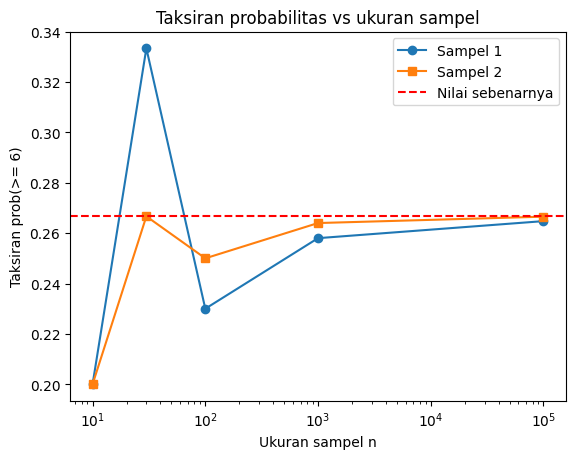

Cek vs manual (taksiran n=100000, toleransi 0.01): SAMA


In [ ]:
menit_telat = np.arange(1, 11)
p_emp = np.array([2, 3, 8, 4, 5, 3, 2, 0, 1, 2]) / 30
hasil = []
for n in [10, 30, 100, 1000, 100_000]:
    s1 = rng.choice(menit_telat, size=n, p=p_emp)
    s2 = rng.choice(menit_telat, size=n, p=p_emp)
    hasil.append((n, np.mean(s1 >= 6), np.mean(s2 >= 6)))
tab = pd.DataFrame(hasil, columns=["n", "Sampel 1", "Sampel 2"])
tab["Selisih"] = (tab["Sampel 1"] - tab["Sampel 2"]).abs()
print(tab.to_string(index=False, float_format="{:.4f}".format))
print(f"Nilai sebenarnya = {8/30:.4f}")
g0_est = hasil[-1][1]
g0_sel_kecil, g0_sel_besar = tab["Selisih"][:3].max(), tab.loc[4, "Selisih"]

plt.semilogx(tab["n"], tab["Sampel 1"], "o-", label="Sampel 1")
plt.semilogx(tab["n"], tab["Sampel 2"], "s-", label="Sampel 2")
plt.axhline(8 / 30, color="red", ls="--", label="Nilai sebenarnya")
plt.xlabel("Ukuran sampel n"); plt.ylabel("Taksiran prob(>= 6)"); plt.legend()
plt.title("Taksiran probabilitas vs ukuran sampel")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (taksiran n=100000, toleransi 0.01):", cocok(8/30, g0_est, 0.01))

**Interpretasi G0:** Pada sampel kecil (n = 10, 30, 100) selisih terbesar antara dua sampel mencapai 0,0667 (pada n = 10 kedua sampel kebetulan sama, tetapi itu tidak berarti taksirannya andal), sedangkan pada n = 100.000 selisihnya hanya 0,0018; taksiran terakhir 0,2648 sangat dekat dengan nilai sebenarnya 0,2667. Jadi sampel kecil bisa menghasilkan taksiran yang berbeda-beda, dan makin besar n makin stabil. Inilah alasan mengapa Definisi 2 memerlukan n yang besar.

#### Soal G1 — Menaksir π

**Soal:** Titik acak (x, y) dibangkitkan di dalam persegi [0,1] × [0,1]. Peluang titik jatuh di dalam seperempat lingkaran (x²+y² ≤ 1) adalah π/4. Taksir π dari simulasi 1.000.000 titik.

**Hitungan manual:**

Luas seperempat lingkaran = π/4, luas persegi = 1 → P(di dalam) = π/4, sehingga π ≈ 4 × (proporsi titik di dalam).

Taksiran pi = 3.14194 | pi sebenarnya = 3.14159 | galat = 0.00035


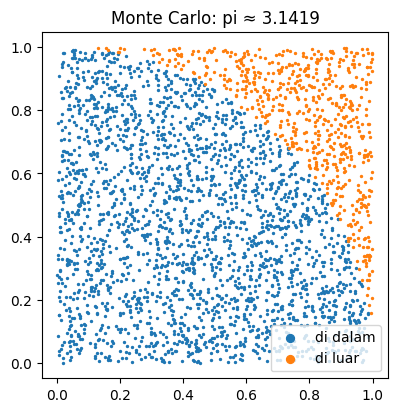

Cek vs manual (taksiran pi, toleransi 0.01): SAMA


In [ ]:
N = 1_000_000
x, y = rng.random(N), rng.random(N)
dalam = x**2 + y**2 <= 1
g1_pi = 4 * dalam.mean()
g1_err = abs(g1_pi - math.pi)
print(f"Taksiran pi = {g1_pi:.5f} | pi sebenarnya = {math.pi:.5f} | galat = {g1_err:.5f}")

plt.figure(figsize=(4.5, 4.5))
idx = slice(0, 3000)
plt.scatter(x[idx][dalam[idx]], y[idx][dalam[idx]], s=2, label="di dalam")
plt.scatter(x[idx][~dalam[idx]], y[idx][~dalam[idx]], s=2, label="di luar")
plt.title(f"Monte Carlo: pi ≈ {g1_pi:.4f}")
plt.legend(markerscale=4); plt.gca().set_aspect("equal")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (taksiran pi, toleransi 0.01):", cocok(3.14159, g1_pi, 0.01))

**Interpretasi G1:** Simulasi 1 juta titik menaksir π ≈ 3,14194 dengan galat hanya 0,00035. Ini menunjukkan simulasi acak dapat menaksir besaran matematis yang sulit dihitung langsung; galatnya menyusut sebanding 1/√N.

#### Soal G2 — Verifikasi jumlah dua dadu = 7

**Soal:** Simulasikan 200.000 lemparan dua dadu dan bandingkan frekuensi jumlah = 7 dengan peluang teori 1/6 (soal A1).

**Hitungan manual:**

Peluang teori P = 1/6 ≈ 0,16667.

Simulasi = 0.16675 | Teori = 0.16667 | selisih = 0.00009


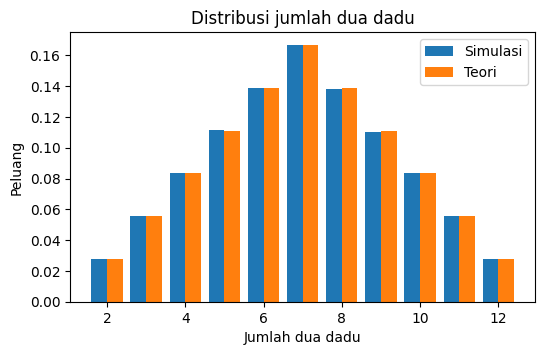

Cek vs manual (P(jumlah=7), toleransi 0.005): SAMA


In [ ]:
N = 200_000
d1, d2 = rng.integers(1, 7, N), rng.integers(1, 7, N)
g2_sim = np.mean(d1 + d2 == 7)
print(f"Simulasi = {g2_sim:.5f} | Teori = {1/6:.5f} | selisih = {abs(g2_sim - 1/6):.5f}")

jumlah = pd.Series(d1 + d2).value_counts(normalize=True).sort_index()
teori = pd.Series({k: (6 - abs(k - 7)) / 36 for k in range(2, 13)})
plt.figure(figsize=(6, 3.5))
plt.bar(jumlah.index - 0.2, jumlah.values, width=0.4, label="Simulasi")
plt.bar(teori.index + 0.2, teori.values, width=0.4, label="Teori")
plt.xlabel("Jumlah dua dadu"); plt.ylabel("Peluang"); plt.legend(); plt.title("Distribusi jumlah dua dadu")
plt.show()

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (P(jumlah=7), toleransi 0.005):", cocok(1/6, g2_sim, 0.005))

**Interpretasi G2:** Frekuensi simulasi 0,1668 sangat dekat dengan teori 0,1667. Grafik memperlihatkan seluruh distribusi jumlah dua dadu berbentuk segitiga dengan puncak di 7, cocok dengan perhitungan.

#### Soal G3 — Masalah Monty Hall

**Soal:** Ada 3 pintu, satu berisi hadiah. Anda memilih satu pintu, pembawa acara (yang tahu isi pintu) membuka satu pintu kosong lain, lalu menawarkan Anda berganti pintu. Simulasikan perilaku pembawa acara, lalu bandingkan peluang menang jika tetap vs berganti.

**Hitungan manual:**

Tetap: menang jika pilihan awal benar = 1/3.
Berganti: menang jika pilihan awal salah (pembawa acara pasti membuka pintu kosong, sehingga pintu sisa berisi hadiah) = 2/3.

In [ ]:
N = 100_000
hadiah = rng.integers(0, 3, N)                      # pintu berisi hadiah
pilihan = rng.integers(0, 3, N)                     # pilihan awal pemain
# Pembawa acara membuka pintu yang BUKAN pilihan pemain dan BUKAN hadiah:
#  - bila pilihan benar (hadiah = pilihan): ada 2 pintu kosong, dipilih acak satu
#  - bila pilihan salah: hanya ada 1 pintu kosong, jadi pintu itu yang dibuka
buka = np.where(pilihan == hadiah,
                (pilihan + 1 + rng.integers(0, 2, N)) % 3,
                3 - pilihan - hadiah)
assert np.all(buka != pilihan) and np.all(buka != hadiah)   # aturan permainan terpenuhi
sisa = 3 - pilihan - buka                           # satu-satunya pintu lain yang masih tertutup
g3_tetap = np.mean(pilihan == hadiah)
g3_ganti = np.mean(sisa == hadiah)                  # dihitung dari simulasi, bukan ~g3_tetap
print(f"Tetap   : {g3_tetap:.4f}  (teori 0.3333)")
print(f"Berganti: {g3_ganti:.4f}  (teori 0.6667)")
print(f"Tetap + berganti = {g3_tetap + g3_ganti:.4f}")

# Pembanding dengan angka pada hitungan manual
print("Cek vs manual (tetap, toleransi 0.01):", cocok(1/3, g3_tetap, 0.01))
print("Cek vs manual (berganti, toleransi 0.01):", cocok(2/3, g3_ganti, 0.01))

Tetap   : 0.3386  (teori 0.3333)
Berganti: 0.6614  (teori 0.6667)
Tetap + berganti = 1.0000
Cek vs manual (tetap, toleransi 0.01): SAMA
Cek vs manual (berganti, toleransi 0.01): SAMA


**Interpretasi G3:** Strategi berganti menang 66,1% sedangkan tetap hanya 33,9%, sesuai teori 2/3 vs 1/3. Kali ini perilaku pembawa acara ikut disimulasikan (membuka pintu kosong yang bukan pilihan pemain), dan kemenangan 'berganti' dihitung dari pintu tersisa, bukan dari kebalikan 'tetap'. Pembawa acara memberi informasi tambahan sehingga peluang pilihan awal tetap 1/3 sementara pintu sisa menjadi 2/3.

---
## Kesimpulan Umum
1. Probabilitas klasik dapat diselesaikan dengan **pencacahan ruang sampel** (`itertools`, `Fraction`) sehingga hasilnya eksak dan dapat dicocokkan dengan hitungan manual.
2. Permutasi dan kombinasi tersedia langsung lewat `math.perm` dan `math.comb`; hasilnya konsisten dengan pencacahan `itertools`.
3. Peluang gabungan, bersyarat, dan independensi dapat diuji dengan **operasi himpunan** Python; beberapa hasil kontra-intuitif (D4, E2, E7) terkonfirmasi lewat pencacahan.
4. Teorema Bayes menunjukkan pentingnya **peluang awal (prior)**: alarm 95% akurat belum tentu berarti 95% benar (F2).
5. Simulasi Monte Carlo memberi hasil mendekati teori saat jumlah percobaan besar (G1–G7), dan berguna ketika perhitungan eksak sulit.